# 📘 14 — ML: Preprocessing, Regression & Gradient Descent
*Part of the Full Stack Data Science & AI booklet. Run cells top to bottom (Shift + Enter). Install libraries first: `pip install -r ../requirements.txt`.*

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import os, sys, math, random, json, time, copy, warnings
from IPython.display import display
warnings.filterwarnings("ignore")

# 1️⃣5️⃣ Machine Learning
**ML = teaching computers to learn patterns from data instead of writing rules by hand.**
| Type | Learns from | Example | Algorithms |
|---|---|---|---|
| Supervised – Regression | labelled data, predicts a number | house price | Linear, Ridge, Lasso, Trees |
| Supervised – Classification | labelled data, predicts a class | spam / not spam | Logistic, KNN, Trees, RF |
| Unsupervised | no labels | customer groups | K-Means, PCA |
| Reinforcement | rewards | game AI | Q-learning |

### The ML workflow
`Problem → Data → EDA → Preprocess → Split → Train → Evaluate → Tune → Deploy`
Install: `pip install scikit-learn`

## 15.1 Data preprocessing pipeline
Steps: handle missing values → encode categories → scale numbers → **split train/test** (avoid *data leakage*: fit transformers on train only!).

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

pas = pd.read_csv("data/passengers.csv")
X, y = pas.drop(columns="survived"), pas["survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

num_cols, cat_cols = ["age", "fare", "pclass"], ["sex", "embarked"]
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])
Xt = preprocess.fit_transform(X_train)          # fit ONLY on train
print("Processed shape:", Xt.shape)
print(preprocess.get_feature_names_out())

# Quick reference for the individual steps
print(StandardScaler().fit_transform([[1], [2], [3]]).ravel(), MinMaxScaler().fit_transform([[1], [2], [3]]).ravel())
print(LabelEncoder().fit_transform(["cat", "dog", "cat"]), pd.get_dummies(pd.Series(["a", "b", "a"])).astype(int).values.tolist())

(400, 5) (100, 5)
Processed shape: (400, 8)
['num__age' 'num__fare' 'num__pclass' 'cat__sex_female' 'cat__sex_male'
 'cat__embarked_C' 'cat__embarked_Q' 'cat__embarked_S']
[-1.22474487  0.          1.22474487] [0.  0.5 1. ]
[0 1 0] [[1, 0], [0, 1], [1, 0]]


#### 🔍 How the pipeline works
- `train_test_split(..., stratify=y)` keeps the **same class ratio** in train and test (important for imbalanced data).
- `SimpleImputer` fills missing values; `StandardScaler` rescales numbers; `OneHotEncoder` converts categories; `ColumnTransformer` applies **different steps to different columns**; `Pipeline` chains the steps.
- `fit_transform` on train **learns** the statistics (mean, categories) and applies them; later `transform` on test/new data **re-uses** them → **no data leakage**.
#### 💼 Where it's used
Pipelines are the professional standard: one object = preprocessing + model, so the exact same steps run in training and in production.

## 15.1b Data preprocessing on the classic `Data.csv`
Raw data is messy. This 10-row file has **everything wrong at once**: missing `Age`, missing `Salary`, text in `State`, a Yes/No target in `Purchased`.

In [3]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
raw = pd.read_csv("data/Data.csv"); print(raw, "\n"); print(raw.isnull().sum().to_dict())

X = raw.iloc[:, :-1].copy(); y = raw.iloc[:, -1]
# 1) Missing values: replace with the column mean
imp = SimpleImputer(missing_values=np.nan, strategy="mean")
X[["Age", "Salary"]] = imp.fit_transform(X[["Age", "Salary"]])
# 2) Categorical feature -> one-hot columns
X = pd.get_dummies(X, columns=["State"], dtype=int)
# 3) Target Yes/No -> 1/0
y = LabelEncoder().fit_transform(y)
# 4) Split BEFORE scaling, fit the scaler on train only (prevents data leakage)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=1)
sc = StandardScaler(); cols = ["Age", "Salary"]
Xtr[cols] = sc.fit_transform(Xtr[cols]); Xte[cols] = sc.transform(Xte[cols])
print(Xtr.round(2)); print("y_train:", ytr)

     State   Age   Salary Purchased
0   France  44.0  72000.0        No
1    Spain  27.0  48000.0       Yes
2  Germany  30.0  54000.0        No
3    Spain  38.0  61000.0        No
4  Germany  40.0      NaN       Yes
5   France  35.0  58000.0       Yes
6    Spain   NaN  52000.0        No
7   France  48.0  79000.0       Yes
8  Germany  50.0  83000.0        No
9   France  37.0  67000.0       Yes 

{'State': 0, 'Age': 1, 'Salary': 1, 'Purchased': 0}
    Age  Salary  State_France  State_Germany  State_Spain
6 -0.19   -1.08             0              0            1
4 -0.01   -0.07             0              1            0
0  0.57    0.63             1              0            0
3 -0.30   -0.31             0              0            1
1 -1.90   -1.42             0              0            1
7  1.15    1.23             1              0            0
8  1.44    1.57             0              1            0
5 -0.74   -0.56             1              0            0
y_train: [0 1 0 0 1 1 0 1]


#### 🔍 How it works
- `SimpleImputer(strategy="mean")` learns the mean (`fit`) and fills gaps (`transform`); `fit_transform` does both. Other strategies: `median`, `most_frequent`, `constant`.
- **One-hot encoding** → `State_France / State_Germany / State_Spain` (1 if true). Avoids implying France < Spain.
- **LabelEncoder** → for the *target* (No→0, Yes→1). Use OneHot for features, Label for the target.
- **`fit` on train, `transform` on test** → the scaler never sees test data → no leakage, honest evaluation.
#### 💼 Where it's used
Data scientists spend ~60–80% of project time on exactly these steps. In production they are bundled into an sklearn `Pipeline` (shown in 15.1) so the same steps run on new data automatically.

## 15.2 Simple Linear Regression
Predict a number from **one** feature: **y = m·x + c** (m = slope, c = intercept). The model finds the line with the **smallest squared errors** (Ordinary Least Squares).

marks = 4.70 × hours + 50.60
Predict 8 hours -> 88.2
MAE=5.48  RMSE=6.51  R²=0.815


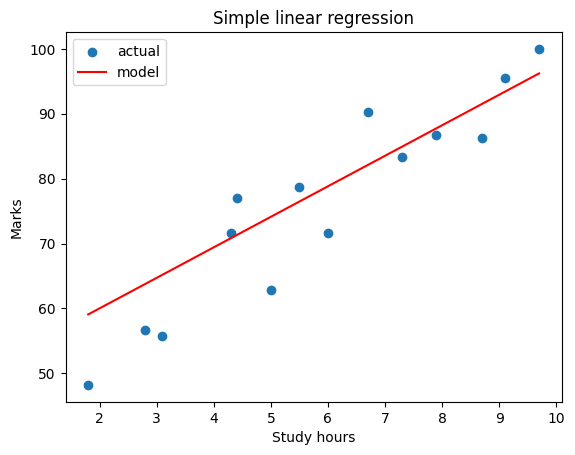

In [4]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

st_df = pd.read_csv("data/students.csv").dropna()
X = st_df[["study_hours"]]; y = st_df["marks"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=0)

model = LinearRegression().fit(Xtr, ytr)
pred = model.predict(Xte)
print(f"marks = {model.coef_[0]:.2f} × hours + {model.intercept_:.2f}")
print("Predict 8 hours ->", model.predict(pd.DataFrame({"study_hours": [8]}))[0].round(1))
print(f"MAE={mean_absolute_error(yte, pred):.2f}  RMSE={mean_squared_error(yte, pred)**.5:.2f}  R²={r2_score(yte, pred):.3f}")

plt.scatter(Xte, yte, label="actual"); plt.plot(Xte.sort_values("study_hours"), model.predict(Xte.sort_values("study_hours")), "r", label="model")
plt.xlabel("Study hours"); plt.ylabel("Marks"); plt.legend(); plt.title("Simple linear regression"); plt.show()

#### 🔍 How it works (line by line)
- `train_test_split(X, y, test_size=0.25, random_state=0)` → keeps 75% to learn from and hides 25% to test honestly; `random_state` makes the split repeatable.
- `LinearRegression().fit(Xtr, ytr)` → finds slope `m` and intercept `c` that minimise the sum of squared errors.
- `model.coef_`, `model.intercept_` → the learned `m` and `c`. `predict()` → plugs new x into `y = m·x + c`.
- Chart: dots = real test points; red line = model's predictions. **Dots close to the line = good model.**
#### 💼 Where it's used
Forecasting (sales from ad spend), pricing, salary estimation, demand planning — and as the **baseline model** every data scientist builds first.

## 15.2b Simple Linear Regression — Salary vs Experience (class dataset)
**Goal:** predict an employee's salary from years of experience. `x` must be 2-D (a table of features), `y` is 1-D (the answer).

{'copy_X': True, 'fit_intercept': True, 'n_jobs': None, 'positive': False, 'tol': 1e-06}
    Actual  Prediction   Error
2    37731     40749.0 -3018.0
28  122391    122700.0  -309.0
13   57081     64962.0 -7881.0
10   63218     63099.0   119.0
26  116969    115250.0  1719.0
24  109431    107800.0  1631.0
Salary = 9313 × years + 26780
Salary for 12 years: 138531.0


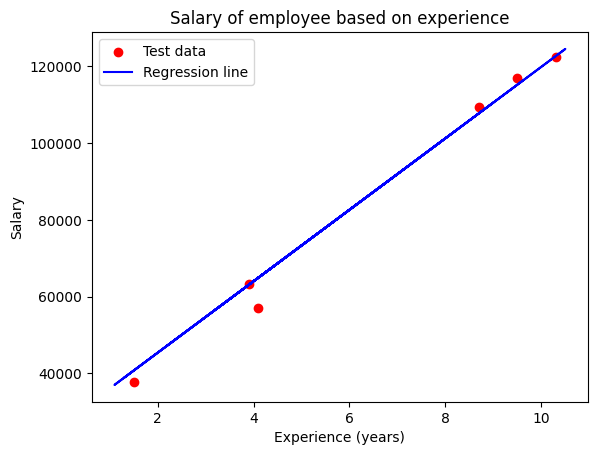

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import pandas as pd, matplotlib.pyplot as plt

dataset = pd.read_csv("data/Salary_Data.csv")
x = dataset.iloc[:, :-1]          # all rows, all columns EXCEPT the last  -> feature(s)  (DataFrame, 2-D)
y = dataset.iloc[:, -1]           # all rows, ONLY the last column         -> target      (Series, 1-D)

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)
regressor = LinearRegression()    # the algorithm (an "empty" model)
regressor.fit(x_train, y_train)   # learning step: finds best slope & intercept
print(regressor.get_params())

y_pred = regressor.predict(x_test)
comparison = pd.DataFrame({"Actual": y_test, "Prediction": y_pred.round(0), "Error": (y_test - y_pred).round(0)})
print(comparison)
print(f"Salary = {regressor.coef_[0]:.0f} × years + {regressor.intercept_:.0f}")
print("Salary for 12 years:", regressor.predict(pd.DataFrame({"YearsExperience": [12]}))[0].round(0))

plt.scatter(x_test, y_test, color="red", label="Test data")
plt.plot(x_train, regressor.predict(x_train), color="blue", label="Regression line")
plt.title("Salary of employee based on experience"); plt.xlabel("Experience (years)"); plt.ylabel("Salary"); plt.legend(); plt.show()

#### 🔍 How it works (line by line)
- `iloc[:, :-1]` → *integer-location* slicing: `:` = all rows, `:-1` = every column except the last. `iloc[:, -1]` = just the last column.
- `fit` → "training": the algorithm calculates the line using **only training data**.
- `predict(x_test)` → predictions for people the model has never seen. The **Comparison table** (Actual vs Prediction vs Error) is how you judge it.
- **Graph:** red dots = real test salaries; blue line = model drawn from the training x-values. Each dot's vertical distance to the line is the error.
#### 💼 Where it's used
HR compensation benchmarking, forecasting revenue from one driver, quick "what-if" estimates. Interview tip: be ready to explain *why we split data* (to detect overfitting).

## 🚀 Mini Project: Student Marks Predictor (full workflow + deployment)
**Business problem:** predict a student's marks from daily study hours. **Workflow used in every ML project:**
`Look at data → Visualise → Clean → Split → Train → Evaluate → Save → Deploy`

(200, 2)


,study_hours,student_marks
0,7.50,46.55
1,8.59,47.36
2,8.10,50.38


,study_hours,student_marks
197,6.24,41.32
198,8.75,48.65
199,7.15,43.43


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   study_hours    195 non-null    float64
 1   student_marks  200 non-null    float64
dtypes: float64(2)
memory usage: 3.3 KB


,study_hours,student_marks
count,195.000000,200.000000
mean,7.019692,42.190550
std,1.165621,5.173417
min,5.010000,30.510000
25%,5.995000,38.230000
50%,7.060000,42.205000
75%,8.035000,46.430000
max,8.980000,53.770000


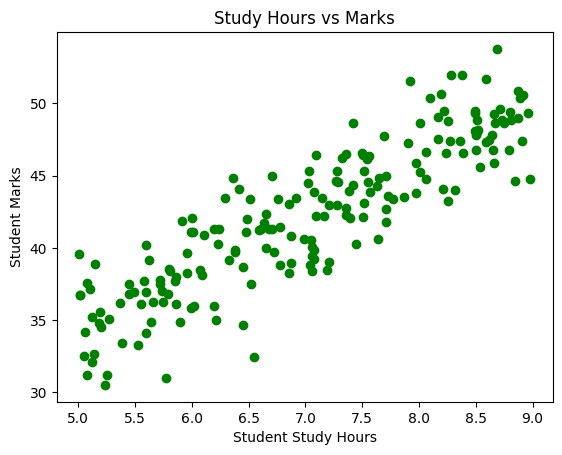

Missing values:
 study_hours      5
student_marks    0
dtype: int64
After fill: 0 missing
Train R² (bias check): 0.727 | Test R² (variance check): 0.795


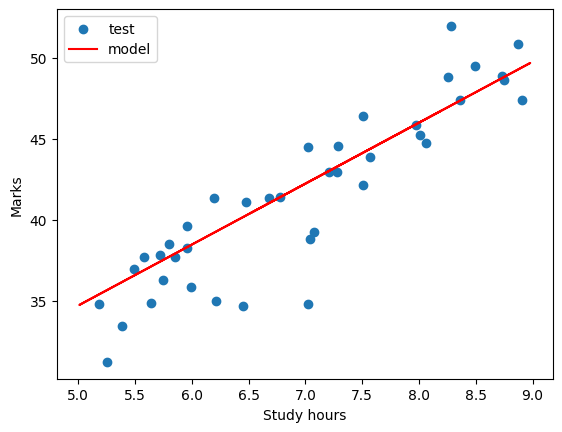

Predicted marks for 7.5 h: 44.1


In [6]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
df = pd.read_csv("data/student_info.csv")
print(df.shape); display(df.head(3)); display(df.tail(3)); df.info(); display(df.describe())

plt.scatter(x=df.study_hours, y=df.student_marks, color="green")        # 1) visualise first
plt.xlabel("Student Study Hours"); plt.ylabel("Student Marks"); plt.title("Study Hours vs Marks"); plt.show()

print("Missing values:\n", df.isnull().sum())                             # 2) clean
df2 = df.fillna(df.mean())                                                # replace NaN with each column's mean
print("After fill:", df2.isnull().sum().sum(), "missing")

X, y = df2.drop("student_marks", axis=1), df2["student_marks"]            # 3) features / target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=51)

lr = LinearRegression().fit(X_train, y_train)                             # 4) train
print("Train R² (bias check):", round(lr.score(X_train, y_train), 3), "| Test R² (variance check):", round(lr.score(X_test, y_test), 3))

plt.scatter(X_test, y_test, label="test"); plt.plot(X_train, lr.predict(X_train), color="r", label="model")   # 5) visualise result
plt.xlabel("Study hours"); plt.ylabel("Marks"); plt.legend(); plt.show()

joblib.dump(lr, "STM_ML.pkl")                                             # 6) save
model = joblib.load("STM_ML.pkl")
print("Predicted marks for 7.5 h:", model.predict(pd.DataFrame({"study_hours": [7.5]}))[0].round(1))

#### 🔍 How it works
- `df.info()` → column types + count of non-missing values; `df.describe()` → count/mean/std/min/quartiles/max — your first data-quality check.
- `df.fillna(df.mean())` → each missing number is replaced by its **column mean** (simple *imputation*; median is safer if outliers exist).
- `drop("student_marks", axis=1)` → `axis=1` means *column*. X = inputs, y = what we predict.
- **Train score vs test score:** both high and close = good fit. High train + low test = **overfitting (high variance)**. Both low = **underfitting (high bias)**.
- `joblib.dump/load` → saves the trained model to a file so an app can reuse it **without re-training**.
#### 💼 Where it's used
This exact pipeline (EDA → clean → split → train → score → save) is how real models reach production. Next step is the app below.

In [7]:
# Deployment: a Streamlit app that loads STM_ML.pkl
deploy = '''
import streamlit as st, joblib, pandas as pd
st.title("🎓 Student Marks Predictor")
model = joblib.load("STM_ML.pkl")
hours = st.number_input("Study hours per day", min_value=0.0, max_value=12.0, value=6.0, step=0.5)
if st.button("Predict marks"):
    pred = model.predict(pd.DataFrame({"study_hours": [hours]}))[0]
    st.success(f"Predicted marks: {pred:.1f}")
'''
open("student_app.py", "w", encoding="utf-8").write(deploy)
print("Saved student_app.py -> run: streamlit run student_app.py   (then deploy free on Streamlit Community Cloud via GitHub)")

Saved student_app.py -> run: streamlit run student_app.py   (then deploy free on Streamlit Community Cloud via GitHub)


**Metrics explained**
- **MAE**: average size of error (easy to understand).
- **MSE / RMSE**: punishes big errors more; RMSE is in the same unit as *y*.
- **R²**: share of variation explained (1 = perfect, 0 = as bad as guessing the mean).

**Assumptions**: linear relation, independent errors, constant error spread, roughly normal residuals, no strong multicollinearity.

## 15.3 Multiple Linear Regression
**y = b0 + b1·x1 + b2·x2 + …** — more than one feature.

area_sqft            0.046
bedrooms             8.050
age_years           -0.632
dist_city_km        -1.248
location_Suburban    2.605
location_Urban       2.785
dtype: float64 
Intercept: 16.07
R²=0.935  Adjusted R²=0.928  RMSE=10.10


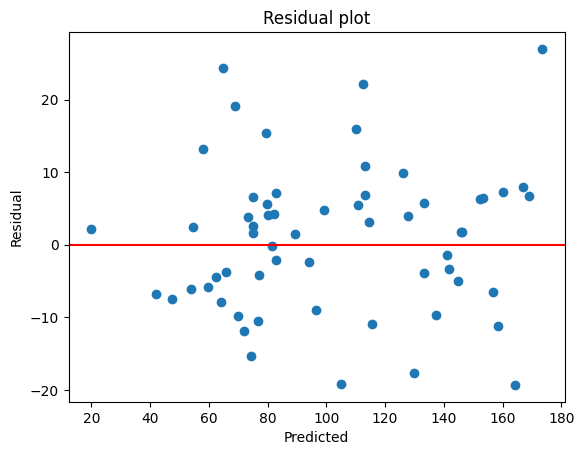

area_sqft            1.03
bedrooms             1.03
age_years            1.01
dist_city_km         1.01
location_Suburban    1.41
location_Urban       1.41
dtype: float64


In [8]:
hs = pd.read_csv("data/houses.csv")
hs = pd.get_dummies(hs, columns=["location"], drop_first=True)          # categorical -> numbers (avoid dummy trap)
X, y = hs.drop(columns="price_lakhs"), hs["price_lakhs"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=1)
mlr = LinearRegression().fit(Xtr, ytr)
print(pd.Series(mlr.coef_, index=X.columns).round(3), "\nIntercept:", round(mlr.intercept_, 2))
pred = mlr.predict(Xte)
r2 = r2_score(yte, pred); n, k = Xte.shape
print(f"R²={r2:.3f}  Adjusted R²={1 - (1 - r2) * (n - 1) / (n - k - 1):.3f}  RMSE={mean_squared_error(yte, pred)**.5:.2f}")

# Residual check: errors should look random around 0
plt.scatter(pred, yte - pred); plt.axhline(0, color="r"); plt.xlabel("Predicted"); plt.ylabel("Residual"); plt.title("Residual plot"); plt.show()

# Multicollinearity check (VIF > 5-10 is a warning)
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
try:
    import statsmodels.api as sm
    Xc = sm.add_constant(X.astype(float))
    print(pd.Series([vif(Xc.values, i) for i in range(1, Xc.shape[1])], index=X.columns).round(2))
except ImportError:
    print("pip install statsmodels to compute VIF")

#### 🔍 How it works
- `pd.get_dummies(..., drop_first=True)` turns text categories into 0/1 columns and drops one to avoid the **dummy-variable trap** (perfect multicollinearity).
- Each **coefficient** = change in price for +1 unit of that feature while others stay fixed (*"all else equal"*). Residual plot should look like **random noise**; a curve/funnel = model is missing something.
- **VIF** (Variance Inflation Factor) measures how much a feature is explained by the other features; > 5–10 means redundant features (multicollinearity).
- **Adjusted R²** adds a penalty for useless features, so it only rises when a new feature really helps.

## 15.3b Multiple Linear Regression — Startup Profit (`Investment.csv`)
**Goal:** which spend drives **Profit** — Research, Marketing or Promotion? Columns: `DigitalMarketing, Promotion, Research, State, Profit`.
**Backward elimination:** fit with all features → remove the one with the highest p-value (> 0.05) → repeat until all remaining features are statistically significant.

In [9]:
import statsmodels.api as sm
inv = pd.read_csv("data/Investment.csv")
print(inv.head(3)); print(inv.State.value_counts().to_dict())

inv = pd.get_dummies(inv, columns=["State"], drop_first=True, dtype=int)   # State (text) -> 0/1 columns
X, y = inv.drop(columns="Profit"), inv["Profit"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=0)
m = LinearRegression().fit(Xtr, ytr)
print(dict(zip(X.columns, m.coef_.round(3).tolist())), "| intercept:", round(float(m.intercept_), 1))
print("Train R²:", round(m.score(Xtr, ytr), 3), "| Test R²:", round(m.score(Xte, yte), 3))

# Backward elimination with statsmodels (gives p-values)
cols = list(X.columns)
while True:
    ols = sm.OLS(y, sm.add_constant(X[cols].astype(float))).fit()
    worst = ols.pvalues.drop("const").idxmax()
    if ols.pvalues[worst] > 0.05: cols.remove(worst); print("removed", worst, "(p =", round(ols.pvalues[worst], 3), ")")
    else: break
print("Final significant features:", cols)
print(ols.summary().tables[1])

   DigitalMarketing  Promotion   Research       State     Profit
0          62770.98  151949.53  142206.61    New York  162459.59
1          76992.49  339133.81  130826.83  California  139960.28
2         124650.42  369846.71  124023.37    New York  158955.01
{'New York': 21, 'Florida': 15, 'California': 14}
{'DigitalMarketing': -0.003, 'Promotion': 0.036, 'Research': 0.771, 'State_Florida': -43.892, 'State_New York': 3568.209} | intercept: 45608.6
Train R²: 0.893 | Test R²: 0.87
removed DigitalMarketing (p = 0.976 )
removed State_Florida (p = 0.835 )
removed State_New York (p = 0.082 )
Final significant features: ['Promotion', 'Research']
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       4.651e+04   5334.691      8.718      0.000    3.58e+04    5.72e+04
Promotion      0.0375      0.009      4.027      0.000       0.019       0.056
Research       0.7722      0.041    

#### 🔍 How it works
- `sm.add_constant` adds the intercept column (statsmodels doesn't add it automatically).
- `ols.pvalues` → probability the feature has **no effect**; p > 0.05 → feature is not significant, so it's dropped.
- The loop removes the *worst* feature one at a time (backward elimination) and refits.
- `summary()` shows coef, std err, t-stat, p-value and 95% CI for each feature.
#### 💼 Where it's used
**Marketing mix modelling** (which spend gives ROI), pricing and risk models. Telling a CEO *"Research spend drives profit; Promotion doesn't"* is exactly the analyst value.

## 15.4 Gradient Descent — how models actually learn
Imagine walking down a hill in fog: at each step you move in the **steepest downhill direction**. The hill = **loss function** (error), a step = **learning rate (α)**.

`new_weight = old_weight − α × gradient`

| Type | Data used per update | Speed | Stability |
|---|---|---|---|
| **Batch GD (BGD)** | all rows | slow on big data | smooth |
| **Stochastic GD (SGD)** | 1 row | fast | noisy |
| **Mini-batch GD** | small chunk (32, 64…) | best balance | good (used in deep learning) |

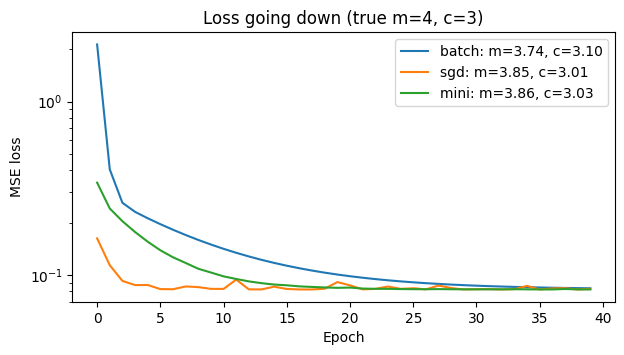

lr=0.001: final loss = 21.3 (too slow)
lr=0.5: final loss = 0.0835 (good)
lr=2.5: final loss = 3.93e+59 (diverges!)
sklearn SGD: [3.54] [3.21]


In [10]:
np.random.seed(0)
Xg = np.random.rand(200); yg = 4 * Xg + 3 + np.random.randn(200) * 0.3     # true: m=4, c=3

def gradient_descent(X, y, lr=0.1, epochs=200, mode="batch", batch=20):
    m, c, history = 0.0, 0.0, []
    n = len(X)
    for _ in range(epochs):
        idx = np.random.permutation(n)
        if mode == "batch":   groups = [idx]
        elif mode == "sgd":   groups = [[i] for i in idx]
        else:                 groups = [idx[i:i + batch] for i in range(0, n, batch)]
        for g in groups:
            xb, yb = X[g], y[g]
            err = (m * xb + c) - yb
            m -= lr * (2 * err * xb).mean()          # d(MSE)/dm
            c -= lr * (2 * err).mean()               # d(MSE)/dc
        history.append(((m * X + c - y) ** 2).mean())
    return m, c, history

plt.figure(figsize=(7, 3.5))
for mode, lr in [("batch", 0.5), ("sgd", 0.02), ("mini", 0.1)]:
    m_, c_, h = gradient_descent(Xg, yg, lr=lr, epochs=40, mode=mode)
    plt.plot(h, label=f"{mode}: m={m_:.2f}, c={c_:.2f}")
plt.xlabel("Epoch"); plt.ylabel("MSE loss"); plt.yscale("log"); plt.legend(); plt.title("Loss going down (true m=4, c=3)"); plt.show()

# Learning-rate effect
for lr in [0.001, 0.5, 2.5]:
    with np.errstate(all="ignore"):
        print(f"lr={lr}: final loss = {gradient_descent(Xg, yg, lr=lr, epochs=40)[2][-1]:.3g}", "(too slow)" if lr == 0.001 else "(good)" if lr == 0.5 else "(diverges!)")

# scikit-learn's SGD version
from sklearn.linear_model import SGDRegressor
sgd = SGDRegressor(max_iter=1000, tol=1e-4, random_state=0).fit(Xg.reshape(-1, 1), yg)
print("sklearn SGD:", sgd.coef_.round(2), sgd.intercept_.round(2))

#### 🔍 How gradient descent works (step by step)
1. Start with a guess `m = 0, c = 0`. 2. Compute the **error** `(m·x + c) − y` for the data. 3. Compute the **gradient** = slope of the loss: `d(MSE)/dm = mean(2·error·x)`, `d(MSE)/dc = mean(2·error)`. 4. Move *against* the gradient: `m −= lr × gradient_m`. 5. Repeat for many **epochs** (one epoch = one pass over the data).
- **Batch**: uses all rows per update (smooth, slow for big data); **SGD**: one row (fast, noisy); **Mini-batch**: small groups (the deep-learning standard).
- **The loss-curve chart:** x = epoch, y = MSE (log scale). A line that falls and flattens = learning has converged. The three lines show how the update style changes speed and smoothness.
- **Learning rate:** too small → painfully slow; right → converges; too big → overshoots and **diverges** (loss explodes).
#### 💼 Where it's used
Gradient descent trains **every neural network and LLM**. Understanding learning rate & batch size is needed for tuning any model.